# Multi Layer Perceptron


In [1]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
%matplotlib inline


In [2]:
#read in all the words
words = open("../data/shakespeare_100k.txt").read().splitlines()
words[:8]

['THE', 'SONNETS', 'ALL', 'IS', 'WELL', 'THAT', 'ENDS', 'WELL']

In [4]:
lookup=sorted(list(set(''.join(words))))
stoi={s:i+1 for i,s in enumerate(lookup)}
stoi['.']=0
itos={i:s for s,i in stoi.items()}

In [ ]:
# build the dataset

window_size = 3 # context length: how many characters we take to predict the next one

X, Y =[], []

for w in words[:5]: # we are just doing for the first 4 words as example
    print(w)
    context = [0]*window_size
    for ch in w + '.':
        ix = stoi[ch]
        X.append(context)
        Y.append(ix)
        print(''.join(itos[i] for i in context), '--->',itos[ix])
        context = context[1:]+[ix] # crop and append
        print()

X=torch.tensor(X)
Y=torch.tensor(Y)

THE
... ---> T

..T ---> H

.TH ---> E

THE ---> .

SONNETS
... ---> S

..S ---> O

.SO ---> N

SON ---> N

ONN ---> E

NNE ---> T

NET ---> S

ETS ---> .

ALL
... ---> A

..A ---> L

.AL ---> L

ALL ---> .

IS
... ---> I

..I ---> S

.IS ---> .

WELL
... ---> W

..W ---> E

.WE ---> L

WEL ---> L

ELL ---> .



In [11]:
X.shape


torch.Size([24, 3])

In [16]:
C = torch.randn((51,2)) # creating embeddings for our 51 chars with evry char rpresented by a 
                        # vector of 2 element (it creates a lookup table)


In [ ]:
emb=C[X]
emb.shape #output = torch.Size([24, 3, 2]) for every 24 tokens in 24X3 matrix there is 2 element vector
          # 2 element vector represents every word in the matrix therefore shape = 24X3X2

torch.Size([24, 3, 2])

In [22]:
W1=torch.randn((6, 100)) # 6 weights per 100 neurons
b1=torch.randn((100)) # 100 biases for 100 neurons


In [24]:
# emb @ W1+b1
'''this wont work because shapes do not match'''

'this wont work because shapes do not match'

In [ ]:
'''to fix the above problem we can use many functions in torch such as concatenate'''
torch.cat([emb[:, 0, :], emb[:, 1, :], emb[:, 2, :]], 1).shape

In [ ]:
emb[:, 0, :].shape # this gives 24X2 embedings of the first(0th) char

# but using cat is ineeficient and takes memory

torch.Size([24, 2])

In [ ]:
# therfore we will use .view()
h=torch.tanh(emb.view(-1, 6) @ W1+b1) # -1 will be infered as the size of embeding rows


In [33]:
W2=torch.randn((100,51))
b2=torch.randn(51)

In [34]:
logits = h @ W2 + b2

In [35]:
counts = logits.exp()


In [39]:
prob = counts/ counts.sum(1, keepdim=True)

In [40]:
prob.shape

torch.Size([24, 51])

In [41]:
torch.arange(24)

tensor([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
        18, 19, 20, 21, 22, 23])

In [43]:
nll=-prob[torch.arange(24),Y].log().mean()
loss=nll

In [45]:
# '''SUMMARY til NOW'''

In [46]:
X.shape, Y.shape # dataset

(torch.Size([24, 3]), torch.Size([24]))

In [48]:
C = torch.randn((51,2))
W1=torch.randn((6, 100))
b1=torch.randn((100)) 
W2=torch.randn((100,51))
b2=torch.randn(51)
parameters = [C, W1, b1, W2, b2]


In [49]:
sum(p.nelement() for p in parameters) # total number of paramters

5953

In [53]:

emb = C[X] #(24,3,2)
h=torch.tanh(emb.view(-1, 6) @ W1+b1) #(24, 100)
logits = h @ W2 + b2 # (24,51)

#these steps are calculating cross entropy loss for softmax layer (output layer) this is obv inefficient
# counts = logits.exp()
# prob = counts/counts.sum(1, keepdim=True)
# loss = -prob[torch.arange(24), Y].log().mean()

# provided torch function to calculate entropy:
loss = F.cross_entropy(logits, Y)
loss

tensor(21.0290)

In [54]:
for p in parameters:
    p.requires_grad=True

In [58]:
for i in range(10):
    # forward pass
    emb = C[X] #(24,3,2)
    h=torch.tanh(emb.view(-1, 6) @ W1+b1) #(24, 100)
    logits = h @ W2 + b2 # (24,51)
    loss = F.cross_entropy(logits, Y)
    print(loss)
    # backward pass

    for p in parameters:
        p.grad = None
    loss.backward()

    # update
    for p in parameters:
        p.data += -0.1 * p.grad

tensor(1.9074, grad_fn=<NllLossBackward0>)
tensor(1.3852, grad_fn=<NllLossBackward0>)
tensor(1.2678, grad_fn=<NllLossBackward0>)
tensor(1.1089, grad_fn=<NllLossBackward0>)
tensor(1.0474, grad_fn=<NllLossBackward0>)
tensor(0.9643, grad_fn=<NllLossBackward0>)
tensor(0.9499, grad_fn=<NllLossBackward0>)
tensor(0.8789, grad_fn=<NllLossBackward0>)
tensor(0.9009, grad_fn=<NllLossBackward0>)
tensor(0.8058, grad_fn=<NllLossBackward0>)


# Now Full Dataset


In [74]:
window_size = 3

X, Y =[], []

for w in words: 
    context = [0]*window_size
    for ch in w + '.':
        ix = stoi[ch]
        X.append(context)
        Y.append(ix)
        context = context[1:]+[ix] # crop and append

X=torch.tensor(X)
Y=torch.tensor(Y)

In [75]:
X.shape, Y.shape

(torch.Size([508574, 3]), torch.Size([508574]))

In [76]:
vocab_size = len(stoi)
embedding_dim = 2

C = torch.randn((vocab_size, embedding_dim))
W1 = torch.randn((window_size * embedding_dim, 100))
b1 = torch.randn(100)

W2 = torch.randn((100, vocab_size))
b2 = torch.randn(vocab_size)

parameters = [C, W1, b1, W2, b2]


In [77]:
sum(p.nelement() for p in parameters) # total number of paramters

6056

In [ ]:
# batch gradient descent
for p in parameters:
    p.requires_grad=True
for i in range(100):
    # forward pass
    emb = C[X] 
    h=torch.tanh(emb.view(-1, 6) @ W1+b1)
    logits = h @ W2 + b2 # (24,51)
    loss = F.cross_entropy(logits, Y)
   
    # backward pass

    for p in parameters:
        p.grad = None
    loss.backward()

    # update
    for p in parameters:
        p.data += -0.9 * p.grad
print(loss.item())

2.928886651992798


In [113]:
# mini batch gradient dscent (randomly slect some xs and optimize the loss of them)

ix = torch.randint(0, X.shape[0], (50,))
# torch.randint(0, X.shape[0], (50,)) # creates random indexes from our data set with batch size 50

for i in range(100):
    # forward pass
    emb = C[X[ix]] 
    h=torch.tanh(emb.view(-1, 6) @ W1+b1)
    logits = h @ W2 + b2 # (24,51)
    loss = F.cross_entropy(logits, Y[ix])
   
    # backward pass

    for p in parameters:
        p.grad = None
    loss.backward()

    # update
    for p in parameters:
        p.data += -0.9 * p.grad
print(loss.item())






0.2698758840560913


# Learning rate optimization

In [114]:
lre=torch.linspace(-3, 0, 100)# .linspace will create 100 numbers between -3 and 0 which is stored in learning rate exponent
lrs= 10**lre
lrs # these are the candidates we want to check for learning rate


tensor([0.0010, 0.0011, 0.0011, 0.0012, 0.0013, 0.0014, 0.0015, 0.0016, 0.0017,
        0.0019, 0.0020, 0.0022, 0.0023, 0.0025, 0.0027, 0.0028, 0.0031, 0.0033,
        0.0035, 0.0038, 0.0040, 0.0043, 0.0046, 0.0050, 0.0053, 0.0057, 0.0061,
        0.0066, 0.0071, 0.0076, 0.0081, 0.0087, 0.0093, 0.0100, 0.0107, 0.0115,
        0.0123, 0.0132, 0.0142, 0.0152, 0.0163, 0.0175, 0.0187, 0.0201, 0.0215,
        0.0231, 0.0248, 0.0266, 0.0285, 0.0305, 0.0327, 0.0351, 0.0376, 0.0404,
        0.0433, 0.0464, 0.0498, 0.0534, 0.0572, 0.0614, 0.0658, 0.0705, 0.0756,
        0.0811, 0.0870, 0.0933, 0.1000, 0.1072, 0.1150, 0.1233, 0.1322, 0.1417,
        0.1520, 0.1630, 0.1748, 0.1874, 0.2009, 0.2154, 0.2310, 0.2477, 0.2656,
        0.2848, 0.3054, 0.3275, 0.3511, 0.3765, 0.4037, 0.4329, 0.4642, 0.4977,
        0.5337, 0.5722, 0.6136, 0.6579, 0.7055, 0.7565, 0.8111, 0.8697, 0.9326,
        1.0000])

In [115]:
lri=[]# learning rate index
lossi=[] # to track the losses for every learning rate

ix = torch.randint(0, X.shape[0], (50000,))
# torch.randint(0, X.shape[0], (50,)) # creates random indexes from our data set with batch size 50

for i in range(100):
    # forward pass
    emb = C[X[ix]] 
    h=torch.tanh(emb.view(-1, 6) @ W1+b1)
    logits = h @ W2 + b2 # (24,51)
    loss = F.cross_entropy(logits, Y[ix])
   
    # backward pass

    for p in parameters:
        p.grad = None
    loss.backward()

    # update
    lr=lrs[i]
    for p in parameters:
        p.data += -lr * p.grad

    # track stats
    lri.append(lre[i])
    lossi.append(loss.item())
print(loss.item())

2.781200408935547


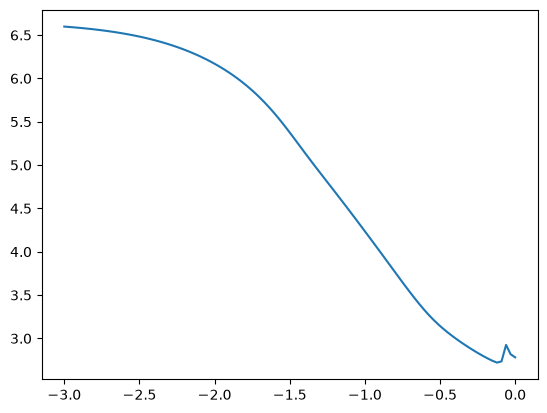

In [116]:
plt.plot(lri, lossi)

In [ ]:
# for 5000 data points los is minimum at lre(0.0001)=10^(-0.0001)=0.6 to 0.7 learning rate
# for 50000 data points as well los is minimum at lre(0.0001)=10^(-0.0001)=0.78 learning rate